# Automatic Speech Recognition (ASR) Model Comparison
This notebook demonstrates comparison of several open-source ASR models with different Datasets.

## Step 1: Setup

#### 1.1. Imports

In [1]:
import os
# Imports
import time
from dataclasses import dataclass
from enum import Enum
from typing import List, Optional

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display, HTML
from datasets import Audio, Dataset, load_dataset
from jiwer import wer
from transformers.pipelines import pipeline

/Users/hsamadov/Projects/_umr/nls-voice-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print(f"PyTorch version: {torch.__version__}")
print(f"Device available: {'CUDA' if torch.cuda.is_available() else 'CPU'}")

PyTorch version: 2.6.0
Device available: CPU


#### 1.2. Enums

In [3]:
class SampleSize(Enum):
    """Sample size categories"""
    TINY = 10
    SMALL = 25
    MEDIUM = 50
    LARGE = 100
    XLARGE = 250
    XXLARGE = 500

#### 1.3.Preferences

In [4]:
# Test Mode
TEST_ENGLISH_ONLY = True
USE_QUICK_TEST = True
SAMPLE_SIZE = SampleSize.TINY

# Directory
CACHE_DIR_DATASETS = "data/cached_datasets"  # Where to cache processed datasets
CACHE_DIR_MODELS = None  # HuggingFace model cache (None = use default ~/.cache/huggingface/)
OUTPUT_DIR = "data/results"  # Where to save results CSV files

In [5]:
# Display Preferences
print("=" * 80)
print("PREFERENCES")
print("=" * 80)
print(f"Test mode: {'Quick' if USE_QUICK_TEST else 'Full'}")
print(f"English only: {TEST_ENGLISH_ONLY}")
print(f"Sample size: {SAMPLE_SIZE.name} ({SAMPLE_SIZE.value} samples)")
print(f"\nDirectories:")
print(f"  Dataset cache: {CACHE_DIR_DATASETS}")
print(f"  Model cache: {CACHE_DIR_MODELS or '~/.cache/huggingface/ (default)'}")
print(f"  Output: {OUTPUT_DIR}")
print("=" * 80)

PREFERENCES
Test mode: Quick
English only: True
Sample size: TINY (10 samples)

Directories:
  Dataset cache: data/cached_datasets
  Model cache: ~/.cache/huggingface/ (default)
  Output: data/results


## Step 2: Helper Classes

#### 2.1. Dataclasses

In [6]:
@dataclass
class DatasetConfig:
    """Configuration for a HuggingFace dataset"""
    name: str
    hf_dataset_name: str
    hf_config: Optional[str] = None
    hf_split: str = "test"
    audio_column: str = "audio"
    text_column: str = "text"
    description: str = ""
    language: str = "en"
    use_streaming: bool = True

In [7]:
@dataclass
class ASRResult:
    """Store results from ASR transcription"""
    model_name: str
    dataset_name: str
    audio_path: str
    transcript: str
    reference_text: str
    time_seconds: float
    wer_score: Optional[float] = None
    language: str = "en"

    def __repr__(self):
        return f"ASRResult({self.model_name}, {self.dataset_name}, WER={self.wer_score:.3f}, Time={self.time_seconds:.2f}s)"

#### 2.2. Managers

In [8]:
class ASRModelManager:
    """Manage loading and running ASR models - Sequential loading"""

    def __init__(self, verbose: bool = True, cache_dir: str = None):
        self.current_model = None
        self.current_model_name = None
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.verbose = verbose
        self.cache_dir = cache_dir

    def load_model(self, model_name: str, model_id: str) -> None:
        """Load a single ASR model from HuggingFace"""
        if self.verbose:
            print(f"📦 Loading {model_name} ({model_id})... ", end="", flush=True)

        # Clear previous model from memory
        if self.current_model is not None:
            del self.current_model
            torch.cuda.empty_cache() if torch.cuda.is_available() else None

        # Set up pipeline kwargs
        pipeline_kwargs = {
            "device": 0 if self.device == "cuda" else -1
        }

        # Add cache_dir if specified
        if self.cache_dir:
            pipeline_kwargs["model_kwargs"] = {"cache_dir": self.cache_dir}

        self.current_model = pipeline(
            "automatic-speech-recognition",
            model=model_id,
            **pipeline_kwargs
        )
        self.current_model_name = model_name

        if self.verbose:
            print("✓")

    def transcribe_sample(
        self,
        audio_path: str,
        dataset_name: str,
        reference_text: Optional[str] = None,
        language: str = "en",
        sample_id: int = 0
    ) -> ASRResult:
        """Transcribe a single audio sample"""
        if self.current_model is None:
            raise ValueError("No model loaded. Call load_model() first.")

        start = time.time()
        result = self.current_model(audio_path)
        elapsed = time.time() - start

        transcript = result["text"].lower().strip()
        wer_score = None

        if reference_text:
            wer_score = wer(reference_text.lower(), transcript)

        # Get display path - improved logic
        if isinstance(audio_path, dict):
            if "path" in audio_path and audio_path["path"]:
                display_path = audio_path["path"]
            else:
                # Use dataset name and sample id for in-memory audio
                display_path = f"{dataset_name}_sample_{sample_id+1}"
        elif isinstance(audio_path, str):
            display_path = audio_path
        else:
            display_path = f"{dataset_name}_sample_{sample_id+1}"

        return ASRResult(
            model_name=self.current_model_name,
            dataset_name=dataset_name,
            audio_path=display_path,
            transcript=transcript,
            reference_text=reference_text or "",
            time_seconds=elapsed,
            wer_score=wer_score,
            language=language
        )

    def transcribe_dataset(
        self,
        dataset: Dataset,
        dataset_config: DatasetConfig
    ) -> List[ASRResult]:
        """Transcribe all samples in a dataset with current model"""
        if self.current_model is None:
            raise ValueError("No model loaded. Call load_model() first.")

        results = []
        total = len(dataset)

        if self.verbose:
            print(f"  🎵 Processing {dataset_config.name} ({total} samples)")

        for idx, item in enumerate(dataset):
            audio_data = item["audio"]

            if isinstance(audio_data, dict):
                if "array" in audio_data:
                    audio_input = audio_data
                elif "path" in audio_data:
                    audio_input = audio_data["path"]
                else:
                    print(f"    ⚠️ Skipping sample {idx+1}: No valid audio data")
                    continue
            else:
                audio_input = audio_data

            reference = item.get(dataset_config.text_column)

            if self.verbose:
                # Better display name for audio
                if isinstance(audio_data, dict):
                    if "path" in audio_data and audio_data["path"]:
                        audio_display = audio_data["path"]
                    else:
                        # Use dataset name and index for in-memory audio
                        audio_display = f"{dataset_config.name}_sample_{idx+1}"
                else:
                    audio_display = f"{dataset_config.name}_sample_{idx+1}"

                print(f"    [{idx+1}/{total}] {audio_display}... ", end="", flush=True)

            try:
                result = self.transcribe_sample(
                    audio_path=audio_input,
                    dataset_name=dataset_config.name,
                    reference_text=reference,
                    language=dataset_config.language,
                    sample_id=idx
                )
                results.append(result)

                if self.verbose:
                    print(f"✓ ({result.time_seconds:.2f}s, WER: {result.wer_score:.3f})")
            except Exception as e:
                if self.verbose:
                    print(f"⚠️ Error: {str(e)}")
                continue

        return results

    def cleanup(self):
        """Clean up loaded model"""
        if self.current_model is not None:
            del self.current_model
            self.current_model = None
            self.current_model_name = None
            torch.cuda.empty_cache() if torch.cuda.is_available() else None

In [9]:
class ASRAnalyzer:
    """Analyze and visualize ASR results"""

    @staticmethod
    def results_to_dataframe(results: List[ASRResult]) -> pd.DataFrame:
        """Convert list of results to pandas DataFrame"""
        return pd.DataFrame([
            {
                "model": r.model_name,
                "dataset": r.dataset_name,
                "language": r.language,
                "audio_path": r.audio_path,
                "reference": r.reference_text,
                "transcript": r.transcript,
                "time_s": r.time_seconds,
                "wer": r.wer_score
            }
            for r in results
        ])

    @staticmethod
    def display_summary(df: pd.DataFrame) -> None:
        """Display summary statistics as formatted table"""
        summary = df.groupby(["model", "dataset"]).agg({
            "time_s": ["mean", "std"],
            "wer": ["mean", "std", "count"]
        }).round(3)

        summary.columns = ['_'.join(col).strip() for col in summary.columns.values]

        display(HTML("<h3>📊 Model Performance Summary</h3>"))
        display(summary.style.background_gradient(
            cmap='RdYlGn_r',
            subset=[col for col in summary.columns if 'wer' in col]
        ).format(precision=3))

        # Overall best performers
        print("\n🏆 Overall Best Performers:")
        avg_wer = df.groupby("model")["wer"].mean()
        avg_time = df.groupby("model")["time_s"].mean()
        print(f"  Best WER: {avg_wer.idxmin()} ({avg_wer.min():.3f})")
        print(f"  Fastest: {avg_time.idxmin()} ({avg_time.min():.2f}s)")

    @staticmethod
    def plot_comparison(df: pd.DataFrame) -> None:
        """Create visualization comparing models across datasets"""
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))

        # 1. WER by model and dataset
        wer_pivot = df.pivot_table(values='wer', index='model', columns='dataset', aggfunc='mean')
        sns.heatmap(wer_pivot, annot=True, fmt='.3f', cmap='RdYlGn_r',
                    ax=axes[0, 0], cbar_kws={'label': 'WER'})
        axes[0, 0].set_title('WER Heatmap by Model and Dataset', fontweight='bold')
        axes[0, 0].set_xlabel('')

        # 2. Time by model and dataset
        time_pivot = df.pivot_table(values='time_s', index='model', columns='dataset', aggfunc='mean')
        sns.heatmap(time_pivot, annot=True, fmt='.2f', cmap='Blues',
                    ax=axes[0, 1], cbar_kws={'label': 'Time (s)'})
        axes[0, 1].set_title('Inference Time by Model and Dataset', fontweight='bold')
        axes[0, 1].set_xlabel('')

        # 3. Average WER per model
        model_wer = df.groupby('model')['wer'].agg(['mean', 'std']).reset_index()
        axes[1, 0].bar(model_wer['model'], model_wer['mean'], yerr=model_wer['std'],
                       capsize=5, alpha=0.7, color='coral')
        axes[1, 0].set_xlabel('Model')
        axes[1, 0].set_ylabel('Average WER')
        axes[1, 0].set_title('Average WER Across All Datasets', fontweight='bold')
        axes[1, 0].tick_params(axis='x', rotation=45)
        axes[1, 0].grid(axis='y', alpha=0.3)

        # 4. WER by language
        if len(df['language'].unique()) > 1:
            lang_wer = df.groupby(['language', 'model'])['wer'].mean().unstack()
            lang_wer.plot(kind='bar', ax=axes[1, 1], width=0.8)
            axes[1, 1].set_title('Average WER by Language', fontweight='bold')
            axes[1, 1].set_xlabel('Language')
            axes[1, 1].set_ylabel('WER')
            axes[1, 1].legend(title='Model', bbox_to_anchor=(1.05, 1))
            axes[1, 1].grid(axis='y', alpha=0.3)
        else:
            # If only one language, show time comparison
            model_time = df.groupby('model')['time_s'].agg(['mean', 'std']).reset_index()
            axes[1, 1].bar(model_time['model'], model_time['mean'], yerr=model_time['std'],
                           capsize=5, alpha=0.7, color='skyblue')
            axes[1, 1].set_xlabel('Model')
            axes[1, 1].set_ylabel('Average Time (s)')
            axes[1, 1].set_title('Average Inference Time', fontweight='bold')
            axes[1, 1].tick_params(axis='x', rotation=45)
            axes[1, 1].grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.show()

    @staticmethod
    def display_detailed_results(df: pd.DataFrame, model_name: Optional[str] = None,
                                 dataset_name: Optional[str] = None) -> None:
        """Display detailed results with optional filtering"""
        subset = df.copy()

        if model_name:
            subset = subset[subset['model'] == model_name]
        if dataset_name:
            subset = subset[subset['dataset'] == dataset_name]

        title = "📋 Detailed Results"
        if model_name:
            title += f" - Model: {model_name}"
        if dataset_name:
            title += f" - Dataset: {dataset_name}"

        display(HTML(f"<h3>{title}</h3>"))

        styled = subset[['model', 'dataset', 'transcript', 'wer', 'time_s']].style.background_gradient(
            cmap='RdYlGn_r',
            subset=['wer']
        ).format({'wer': '{:.3f}', 'time_s': '{:.2f}'})

        display(styled)

#### 2.3. Dataset Loader

In [10]:
def load_dataset_from_config(config: DatasetConfig) -> Dataset:
    """Load dataset from HuggingFace configuration with streaming support"""
    from datasets import Audio

    # Use global SAMPLE_SIZE
    max_samples = SAMPLE_SIZE.value

    print(f"📥 Loading {config.name} ({max_samples} samples)... ", end="", flush=True)

    if config.use_streaming:
        # Use streaming to avoid downloading entire archives
        from itertools import islice

        dataset_stream = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=config.hf_split,
            streaming=True,
            trust_remote_code=True
        )

        # Shuffle and take only max_samples
        dataset_stream = dataset_stream.shuffle(seed=42, buffer_size=1000)
        samples = list(islice(dataset_stream, max_samples))
        dataset = Dataset.from_list(samples)

        # Cast the audio column to ensure correct numpy format
        if "audio" in dataset.column_names:
            dataset = dataset.cast_column("audio", Audio())
    else:
        # Traditional loading with slice (for smaller datasets)
        dataset = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=f"{config.hf_split}[:{max_samples}]",
            trust_remote_code=True
        )

    # Rename columns to standardize
    if config.text_column != "text" and config.text_column in dataset.column_names:
        dataset = dataset.rename_column(config.text_column, "text")

    if config.audio_column != "audio" and config.audio_column in dataset.column_names:
        dataset = dataset.rename_column(config.audio_column, "audio")

    # Keep only audio and text columns
    columns_to_keep = ["audio", "text"]
    columns_to_remove = [col for col in dataset.column_names if col not in columns_to_keep]
    if columns_to_remove:
        dataset = dataset.remove_columns(columns_to_remove)

    print(f"✓ ({len(dataset)} samples)")
    return dataset

In [11]:
def load_or_create_cached_dataset(config: DatasetConfig, cache_dir: str = None) -> Dataset:
    """Load from cache or create and cache dataset"""
    import os
    from datasets import Audio

    # Use global CACHE_DIR_DATASETS if not specified
    if cache_dir is None:
        cache_dir = CACHE_DIR_DATASETS

    cache_path = os.path.join(cache_dir, f"{config.name.lower().replace(' ', '_')}")

    if os.path.exists(cache_path):
        print(f"📂 Loading {config.name} from cache... ", end="", flush=True)
        dataset = Dataset.load_from_disk(cache_path)
        print(f"✓ ({len(dataset)} samples)")
        return dataset
    else:
        dataset = load_dataset_from_config(config)

        # Ensure audio column is properly formatted before caching
        if "audio" in dataset.column_names:
            dataset = dataset.cast_column("audio", Audio())

        os.makedirs(cache_dir, exist_ok=True)
        dataset.save_to_disk(cache_path)
        print(f"💾 Cached to {cache_path}")
        return dataset

## Step 3: Model & Dataset Configuration

#### 3.1. For English

In [12]:
# Model configurations
ENGLISH_MODELS = {
    "Whisper-Tiny-En": "openai/whisper-tiny.en", # ~39M
    "Whisper-Base-En": "openai/whisper-base.en", # ~74M
    "Whisper-Small-En": "openai/whisper-small.en", # ~244M
    # "Whisper-Medium-En": "openai/whisper-medium.en", # ~769M
    "Distil-Whisper-Small-En": "distil-whisper/distil-small.en", # ~166M
    "Distil-Whisper-Medium-En": "distil-whisper/distil-medium.en", # ~394M
}

In [13]:
ENGLISH_DATASETS = [
    # LibriSpeech - Clean audiobooks
    DatasetConfig(
        name="LibriSpeech_Clean",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="clean",
        hf_split="test",
        description="Clean audiobook recordings",
        language="en"
    ),

    # LibriSpeech - Other
    DatasetConfig(
        name="LibriSpeech_Other",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="other",
        hf_split="test",
        description="Challenging audiobook recordings",
        language="en"
    ),

    # AMI - Meeting recordings
    DatasetConfig(
        name="AMI_Meetings",
        hf_dataset_name="edinburghcstr/ami",
        hf_config="ihm",
        hf_split="test",
        description="Meeting recordings - conversational speech",
        language="en"
    ),

    # FLEURS - English (US)
    DatasetConfig(
        name="FLEURS_English_US",
        hf_dataset_name="google/fleurs",
        hf_config="en_us",
        hf_split="test",
        text_column="transcription",
        description="FLEURS English (US) - diverse topics",
        language="en"
    ),

    # People's Speech
    DatasetConfig(
        name="PeoplesSpeech",
        hf_dataset_name="MLCommons/peoples_speech",
        hf_split="train",
        text_column="text_normalized",
        description="Public speeches - diverse speaking styles",
        language="en"
    ),
]

#### 3.2. Others

In [20]:
OTHER_MODELS = {
    # Whisper multilingual
    "Whisper-Tiny": "openai/whisper-tiny", # ~39M
    "Whisper-Base": "openai/whisper-base", # ~74M
    "Whisper-Small": "openai/whisper-small", # ~244M
    # "Whisper-Medium": "openai/whisper-medium", # ~769M

    # Distilled Whisper (multilingual)
    # "Distil-Whisper-Large-V3.5": "distil-whisper/distil-large-v3.5", # ~756M

    # Self-supervised / speech representation models
    "HuBERT-Large": "facebook/hubert-large-ls960-ft", # ~316M
    "Wav2Vec2-Base": "facebook/wav2vec2-base-960h", # ~95M
    "Wav2Vec2-Large": "facebook/wav2vec2-large-960h-lv60-self", # ~317M
}

In [21]:
OTHER_LANGUAGE_DATASETS = [
    # German
    DatasetConfig(
        name="MLS_German",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="german",
        hf_split="test",
        description="Multilingual LibriSpeech - German audiobooks",
        language="de"
    ),

    DatasetConfig(
        name="FLEURS_German",
        hf_dataset_name="google/fleurs",
        hf_config="de_de",
        hf_split="test",
        text_column="transcription",
        description="FLEURS German",
        language="de"
    ),

    # Spanish
    DatasetConfig(
        name="MLS_Spanish",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="spanish",
        hf_split="test",
        description="Multilingual LibriSpeech - Spanish audiobooks",
        language="es"
    ),

    DatasetConfig(
        name="FLEURS_Spanish",
        hf_dataset_name="google/fleurs",
        hf_config="es_419",
        hf_split="test",
        text_column="transcription",
        description="FLEURS Spanish (Latin America)",
        language="es"
    ),

    # French
    DatasetConfig(
        name="MLS_French",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="french",
        hf_split="test",
        description="Multilingual LibriSpeech - French audiobooks",
        language="fr"
    ),

    DatasetConfig(
        name="FLEURS_French",
        hf_dataset_name="google/fleurs",
        hf_config="fr_fr",
        hf_split="test",
        text_column="transcription",
        description="FLEURS French",
        language="fr"
    ),

    # Italian
    DatasetConfig(
        name="MLS_Italian",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="italian",
        hf_split="test",
        description="Multilingual LibriSpeech - Italian audiobooks",
        language="it"
    ),

    # Dutch
    DatasetConfig(
        name="MLS_Dutch",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="dutch",
        hf_split="test",
        description="Multilingual LibriSpeech - Dutch audiobooks",
        language="nl"
    ),

    # Portuguese
    DatasetConfig(
        name="MLS_Portuguese",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="portuguese",
        hf_split="test",
        description="Multilingual LibriSpeech - Portuguese audiobooks",
        language="pt"
    ),

    # Polish
    DatasetConfig(
        name="MLS_Polish",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config="polish",
        hf_split="test",
        description="Multilingual LibriSpeech - Polish audiobooks",
        language="pl"
    ),
]

In [ ]:
MUSIC_DATASETS = [
    DatasetConfig(
        name="Jamendo_Lyrics_EN",
        hf_dataset_name="jamendolyrics/jam-alt",
        hf_split="train",
        audio_column="audio",
        text_column="lyrics",
        description="English songs with lyrics - singing vocals",
        language="en",
        dataset_type="music"
    ),
    DatasetConfig(
        name="Jamendo_Lyrics_MultiLang",
        hf_dataset_name="jamendolyrics/jam-alt",
        hf_split="train",
        audio_column="audio",
        text_column="lyrics",
        description="Multi-language songs with lyrics",
        language="multi",
        dataset_type="music"
    ),
]

#### 3.3. Configuration Selections

In [22]:
SELECTED_MODELS =  {**ENGLISH_MODELS, **OTHER_MODELS}

In [23]:
if USE_QUICK_TEST:
    english = ENGLISH_DATASETS[:2]
    other = OTHER_LANGUAGE_DATASETS[:2]
else:
    english = ENGLISH_DATASETS
    other = OTHER_LANGUAGE_DATASETS

SELECTED_DATASETS = english if TEST_ENGLISH_ONLY else (english + other)

## Step 4: Sequential Transcription
Load one model at a time, test on all datasets, then move to next model

In [24]:
# Initialize manager with configured cache directory
manager = ASRModelManager(verbose=True, cache_dir=CACHE_DIR_MODELS)
all_results = []

print(f"🚀 Starting sequential transcription...")
print(f"Device: {manager.device}")
print(f"Model cache: {CACHE_DIR_MODELS or 'Default HF cache'}")
print(f"=" * 80)

🚀 Starting sequential transcription...
Device: cpu
Model cache: Default HF cache


In [25]:
# Loop through each model
for model_idx, (model_name, model_id) in enumerate(SELECTED_MODELS.items(), 1):
    print(f"\n{'='*80}")
    print(f"MODEL {model_idx}/{len(SELECTED_MODELS)}: {model_name}")
    print(f"{'='*80}")

    # Load the model
    manager.load_model(model_name, model_id)

    # Test on all datasets
    for dataset_idx, dataset_config in enumerate(SELECTED_DATASETS, 1):
        print(f"\n  Dataset {dataset_idx}/{len(SELECTED_DATASETS)}: {dataset_config.name}")

        # Load dataset (uses global CACHE_DIR_DATASETS)
        try:
            dataset = load_or_create_cached_dataset(dataset_config, cache_dir=CACHE_DIR_DATASETS)

            # Transcribe
            results = manager.transcribe_dataset(dataset, dataset_config)
            all_results.extend(results)

            # Show quick stats
            if results:
                avg_wer = sum(r.wer_score for r in results if r.wer_score is not None) / len(results)
                avg_time = sum(r.time_seconds for r in results) / len(results)
                print(f"    ✅ Avg WER: {avg_wer:.3f}, Avg Time: {avg_time:.2f}s")
            else:
                print(f"    ⚠️ No successful transcriptions")

        except Exception as e:
            print(f"    ⚠️ Error: {str(e)[:100]}")
            continue

    # Clean up model before loading next
    if model_idx < len(SELECTED_MODELS):
        manager.cleanup()

print(f"\n{'='*80}")
print(f"✅ Completed! Total results: {len(all_results)}")
print(f"{'='*80}")


MODEL 1/11: Whisper-Tiny-En
📦 Loading Whisper-Tiny-En (openai/whisper-tiny.en)... 

Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.66s, WER: 0.065)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.39s, WER: 0.556)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.65s, WER: 0.038)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.12s, WER: 1.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.24s, WER: 0.143)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.31s, WER: 0.062)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.83s, WER: 0.183)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.33s, WER: 0.190)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.14s, WER: 0.200)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.43s, WER: 0.129)
    ✅ Avg WER: 0.257, Avg Time: 0.41s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.16s, WER

Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (1.33s, WER: 0.097)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.65s, WER: 0.389)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (1.11s, WER: 0.077)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.26s, WER: 1.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.46s, WER: 0.143)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.54s, WER: 0.062)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (1.50s, WER: 0.167)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.62s, WER: 0.190)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.30s, WER: 0.200)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.83s, WER: 0.161)
    ✅ Avg WER: 0.249, Avg Time: 0.76s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.37s, WER

...

✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.56s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.39s, WER: 0.333)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (1.16s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.11s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.27s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.26s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.94s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.33s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.16s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.49s, WER: 0.000)
    ✅ Avg WER: 0.037, Avg Time: 0.47s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.11s, WER

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.75s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.14s, WER: 0.333)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.42s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.04s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.10s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.10s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.34s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.12s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.06s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.18s, WER: 0.000)
    ✅ Avg WER: 0.037, Avg Time: 0.23s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.04s, WER

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-large-960h-lv60-self and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cpu


✓

  Dataset 1/2: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (0.57s, WER: 0.032)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.42s, WER: 0.222)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (1.42s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.15s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.33s, WER: 0.000)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.31s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (1.23s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.36s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.17s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.51s, WER: 0.000)
    ✅ Avg WER: 0.025, Avg Time: 0.55s

  Dataset 2/2: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.13s, WER

## Step 5: Results

#### 5.1. Analyze Results

In [26]:
# Convert to DataFrame
analyzer = ASRAnalyzer()
df = analyzer.results_to_dataframe(all_results)

# Display summary statistics
analyzer.display_summary(df)


🏆 Overall Best Performers:
  Best WER: Wav2Vec2-Large (0.025)
  Fastest: Wav2Vec2-Base (0.15s)


#### 2. Visualize Results

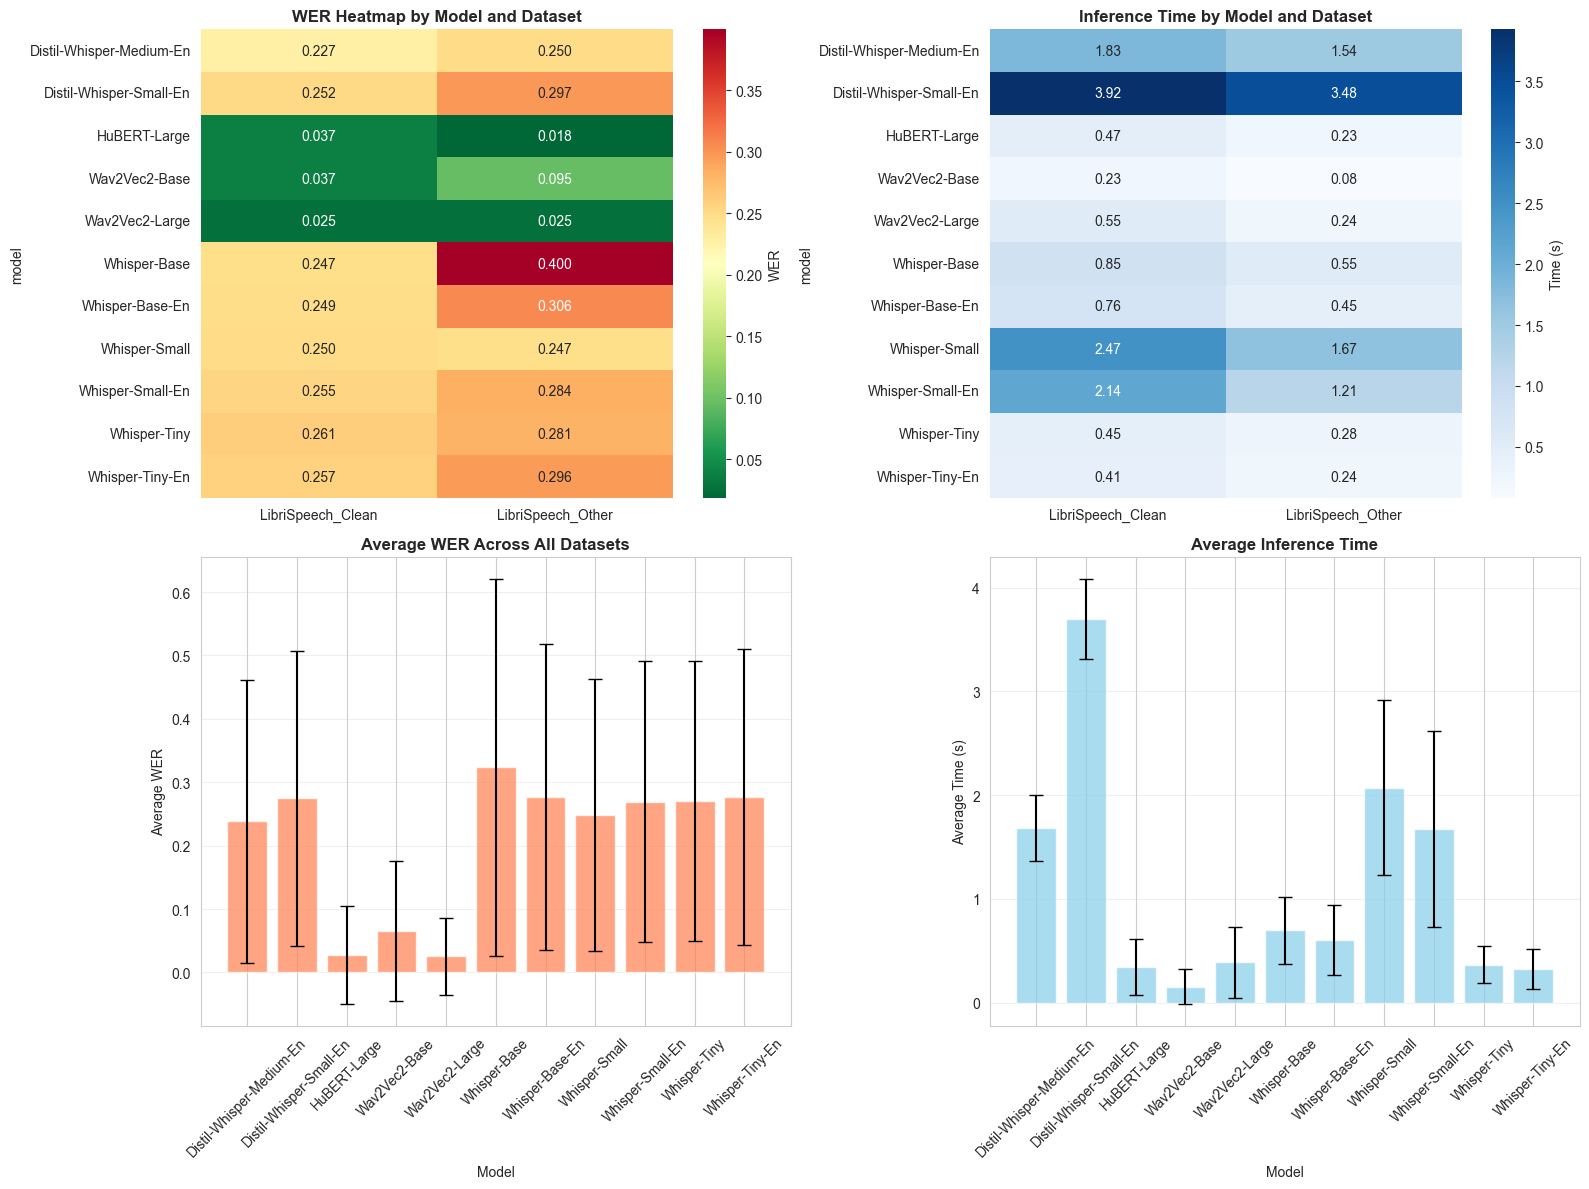

In [27]:
analyzer.plot_comparison(df)

#### 3. Detailed Results Table

In [ ]:
# Show full results table with reference and transcript
display(HTML("<h5>📋 Complete Results</h5>"))

# Create a styled dataframe with better formatting
styled_df = df[['model', 'dataset', 'reference', 'transcript', 'wer', 'time_s']].style\
    .background_gradient(cmap='RdYlGn_r', subset=['wer'])\
    .format({'wer': '{:.3f}', 'time_s': '{:.2f}'})\
    .set_properties(**{
        'text-align': 'left',
        'white-space': 'pre-wrap',
        'max-width': '300px'
    }, subset=['reference', 'transcript'])\
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', 'bold')]},
        {'selector': 'td', 'props': [('padding', '8px')]}
    ])

display(styled_df)

#### 4. Save Results

In [29]:
# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save complete results
output_path = os.path.join(OUTPUT_DIR, "asr_results.csv")
df.to_csv(output_path, index=False)
print(f"💾 Results saved to: {output_path}")

# Save summary by model and dataset
summary_path = os.path.join(OUTPUT_DIR, "asr_summary.csv")
summary_df = df.groupby(['model', 'dataset', 'language']).agg({
    'wer': ['mean', 'std', 'min', 'max'],
    'time_s': ['mean', 'std']
}).round(3)
summary_df.to_csv(summary_path)
print(f"💾 Summary saved to: {summary_path}")

print(f"\n📁 All outputs saved to: {OUTPUT_DIR}")

💾 Results saved to: data/results/asr_results.csv
💾 Summary saved to: data/results/asr_summary.csv

📁 All outputs saved to: data/results
